# Lepton-jet reconstruction efficiency: the DSA muons of prompt muons, in simulation

A displaced dark photon is boosted, so its muons point back to the primary vertex: their true
impact parameter stays small even when the decay is far from the beam line. Prompt muons therefore
test the reconstruction and selection of DSA muons at the impact parameters that matter. This
notebook measures in simulation the fraction of prompt muons that have a DSA muon passing the
lepton-jet source cuts of DSA muons without the cross-cleaning against PF muons (pT > 10 GeV,
|η| < 2.4, displaced ID, η-φ veto), in two samples:

- **Z → μμ**, tag and probe: the tag a tight, isolated muon above 30 GeV, the probe an isolated,
  prompt tracker muon of opposite charge, 81 < m(tag, probe) < 101 GeV with sidebands 10 GeV wide
  (`objects.dsa_probe_muons`); passing when a selected DSA muon lies within ΔR < 0.2.
- **J/ψ → μμ**, the boosted muon pairs of the muon-type control sample: how many of the two muons
  have their own selected DSA muon (ΔR < 0.2), against their separation.

The channels (`dsa_cr_*` in `selections.yaml`) have no trigger, and the histograms carry the
decisions of the analysis triggers (DoubleL2Mu, which need a standalone muon on both legs),
IsoMu24 and Mu37_TkMu27 as axes, so the bias each trigger puts on the probe can be read off. Inputs:
campaign `lj_reco_cr_v3` (simulation only). No data is read here; what a data measurement needs is
in section 5.

In [1]:
import os, shutil, sys, tempfile, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import uproot

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy
import plot_tools as pt   # on the path through systematics_study  # pylint: disable=import-error

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)

INPUT_DIR = sysstudy.eos_url(sysstudy.LJ_CR_V3_DIR)        # the merged outputs of lj_reco_cr_v3
OUTPUT_DIR = sysstudy.eos_url(sysstudy.DSA_RESULTS_DIR)    # the figures and the passing fractions
if not sysstudy.list_coffea(INPUT_DIR):
    raise FileNotFoundError(
        f"No merged outputs in {INPUT_DIR} yet. Run the lj_reco_cr_v3 campaign first, from the "
        "repository root: python condor/campaign.py lj_reco_cr_v3 jobs, then submit, then status "
        "with retry --submit and skipped --submit until every chunk is done, then merge "
        "(condor/README.md, section 23).")
WORK = Path(tempfile.mkdtemp(prefix="dsa_prompt_"))   # removed at the end
DY = sysstudy.LJ_CR_GROUPS[r"DY$\to\ell\ell$"]
TRIGGERS = {"no trigger": {}, "analysis triggers": {"trig_analysis": 1},
            "IsoMu24": {"trig_isomu24": 1}, "Mu37_TkMu27": {"trig_tkmu": 1}}


def save(fig, name):
    """Write a figure into the working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK / f"{name}{suffix}", bbox_inches="tight")


def summed(inputs, cr, samples=None):
    """The probe histogram of one sample of DSA_CR summed over the given background samples
    (every one by default)"""
    return sum(per[cr] for s, per in inputs["background"].items() if samples is None or s in samples)


def show(label, r):
    """Print one probe_efficiency result over its in-range bins"""
    print(f"{label}: " + ", ".join(
        f"{lo:g}-{hi:g}: {e:.3f} +- {u:.3f}" for lo, hi, e, u in zip(
            r["edges"][:-1], r["edges"][1:], sysstudy.in_range(r["axis"], r["eff"]),
            sysstudy.in_range(r["axis"], r["err"]))))


print("inputs: ", INPUT_DIR)
print("outputs:", OUTPUT_DIR)

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v3
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v3_results/dsa_prompt


## 1. Inputs

In [2]:
inputs = sysstudy.lj_cr_inputs(INPUT_DIR, specs=sysstudy.DSA_CR)
print(len(inputs["signal"]), "signal points,", len(inputs["background"]), "background samples\n")
print(f"{'sample':20s} {'group':18s} {'in the peak':>14s} {'effective':>10s} {'sidebands':>12s}")
for cr, group, peak, neff, side in sysstudy.probe_counts(inputs, sysstudy.DSA_CR):
    print(f"{cr:20s} {group:18s} {peak:14.4g} {neff:10.1f} {side:12.4g}")

96 signal points, 18 background samples

sample               group                 in the peak  effective    sidebands
Z -> mumu, DSA       DY$\to\ell\ell$         6.005e+07 18589501.3    3.699e+06
Z -> mumu, DSA       QCD                     1.799e+04       39.0    1.939e+04
Z -> mumu, DSA       $t\bar{t}$              4.644e+04    14236.0    4.523e+04
Z -> mumu, DSA       diboson                 7.614e+04   350153.4    1.123e+04
Z -> mumu, DSA       total                   6.019e+07 17896009.1    3.775e+06
J/psi -> mumu, DSA   DY$\to\ell\ell$         1.978e+04     5459.0     1.92e+04
J/psi -> mumu, DSA   QCD                     7.234e+06     5553.9    1.954e+06
J/psi -> mumu, DSA   $t\bar{t}$               1.11e+04     3402.8         4414
J/psi -> mumu, DSA   diboson                     203.8      660.6        175.6
J/psi -> mumu, DSA   total                   7.265e+06     5601.7    1.978e+06


**Interpretation (run of 2026-11-24: `lj_reco_cr_v3`).** Drell-Yan gives 60 million
$Z \to \mu\mu$ probes in the peak at the luminosity of 2018 (18.6 million effective simulated
events), against 3.7 million in the sidebands: the sample is nearly pure, and the simulation's
statistics are no limit. The $J/\psi$ pairs come almost entirely from QCD (7.2 of 7.3 million in
the peak), with 5,600 effective events, which limits the precision of section 4.

## 2. The displaced ID has no impact-parameter requirement

If the displaced ID cut on the impact parameter, prompt muons would fail it by construction and
could not test it. The ntuple flag `DSAMuon_displacedID` stands for four cuts on the hits and the
fit (DT + CSC hits > 12, at least 19 DT hits when there is no CSC hit, χ²/ndof < 2.5,
σ(pT)/pT < 1), the individual cuts of `cuts.py`. On one Drell-Yan file of the inputs, the flag and
the four cuts agree for every DSA muon, so nothing else enters it.

In [3]:
URL = ("root://cmseos.fnal.gov//store/group/lpcmetx/SIDM/Backgrounds/2018_v2/Skims/"
       "DYJetsToLL_M50_LLPnanoAODv1/skimmed_output_1.root")
branches = ["DSAMuon_displacedID", "DSAMuon_trkNumDTHits", "DSAMuon_trkNumCSCHits",
            "DSAMuon_normChi2", "DSAMuon_ptErr", "DSAMuon_pt", "DSAMuon_dxy"]
with uproot.open(URL) as f:
    a = {b: np.concatenate(list(f["Events"][b].array(library="np"))) for b in branches}
flag = a["DSAMuon_displacedID"] > 0
dt, csc = a["DSAMuon_trkNumDTHits"], a["DSAMuon_trkNumCSCHits"]
cuts = ((dt + csc > 12) & ~((csc == 0) & (dt <= 18)) & (a["DSAMuon_normChi2"] < 2.5)
        & (a["DSAMuon_ptErr"] / a["DSAMuon_pt"] < 1))
print(f"{len(flag)} DSA muons: {flag.sum()} pass the flag, {cuts.sum()} the four cuts, "
      f"{(flag == cuts).sum()} agree")
print("|dxy| of the passing ones (cm), median, 90% and 99% quantiles:",
      np.round(np.quantile(np.abs(a["DSAMuon_dxy"][flag]), [0.5, 0.9, 0.99]), 1))

6964 DSA muons: 4118 pass the flag, 4118 the four cuts, 6964 agree
|dxy| of the passing ones (cm), median, 90% and 99% quantiles: [ 3.3 21.9 75.6]


**Interpretation.** The flag and the four cuts agree for all 6,964 DSA muons of the file, of
which 4,118 pass: the displaced ID has no requirement on the impact parameter. The passing DSA
muons of this Drell-Yan file, mostly the prompt muons of the $Z$, have a median $|d_{xy}|$ of
3.3 cm (90% below 21.9 cm, 99% below 75.6 cm): without tracker hits, the impact parameter of a
prompt muon is measured only to centimeters. Prompt muons therefore test the DSA selection as it
acts on the muons of displaced, boosted dark photons.

## 3. Prompt muons of Z → μμ

The passing fraction against the probe's pT and |η|, in Drell-Yan simulation, for each trigger.
Without a trigger (possible in simulation only) the probe is unbiased; the analysis triggers need
a standalone muon on both legs, so with them a probe has a reconstructed standalone muon more
often; IsoMu24 can be fired by the tag alone; the second leg of Mu37_TkMu27 needs only a tracker
muon. The sidebands are subtracted as in data, although the Drell-Yan probes are nearly pure.

no trigger, probe_pt: 10-20: 0.770 +- 0.001, 20-30: 0.825 +- 0.000, 30-40: 0.818 +- 0.000, 40-50: 0.809 +- 0.000, 50-60: 0.798 +- 0.000, 60-80: 0.788 +- 0.001, 80-120: 0.767 +- 0.001, 120-200: 0.729 +- 0.003
analysis triggers, probe_pt: 10-20: 0.755 +- 0.002, 20-30: 0.855 +- 0.000, 30-40: 0.852 +- 0.000, 40-50: 0.842 +- 0.000, 50-60: 0.831 +- 0.000, 60-80: 0.820 +- 0.001, 80-120: 0.797 +- 0.001, 120-200: 0.761 +- 0.003
IsoMu24, probe_pt: 10-20: 0.770 +- 0.001, 20-30: 0.825 +- 0.000, 30-40: 0.818 +- 0.000, 40-50: 0.810 +- 0.000, 50-60: 0.798 +- 0.000, 60-80: 0.789 +- 0.001, 80-120: 0.767 +- 0.001, 120-200: 0.729 +- 0.003
Mu37_TkMu27, probe_pt: 10-20: 0.796 +- 0.021, 20-30: 0.831 +- 0.001, 30-40: 0.823 +- 0.000, 40-50: 0.816 +- 0.000, 50-60: 0.808 +- 0.000, 60-80: 0.802 +- 0.001, 80-120: 0.777 +- 0.001, 120-200: 0.738 +- 0.003
no trigger, probe_abseta: 0-0.9: 0.846 +- 0.000, 0.9-1.2: 0.785 +- 0.000, 1.2-2.1: 0.832 +- 0.000, 2.1-2.4: 0.556 +- 0.000
analysis triggers, probe_abseta: 0-0.9: 

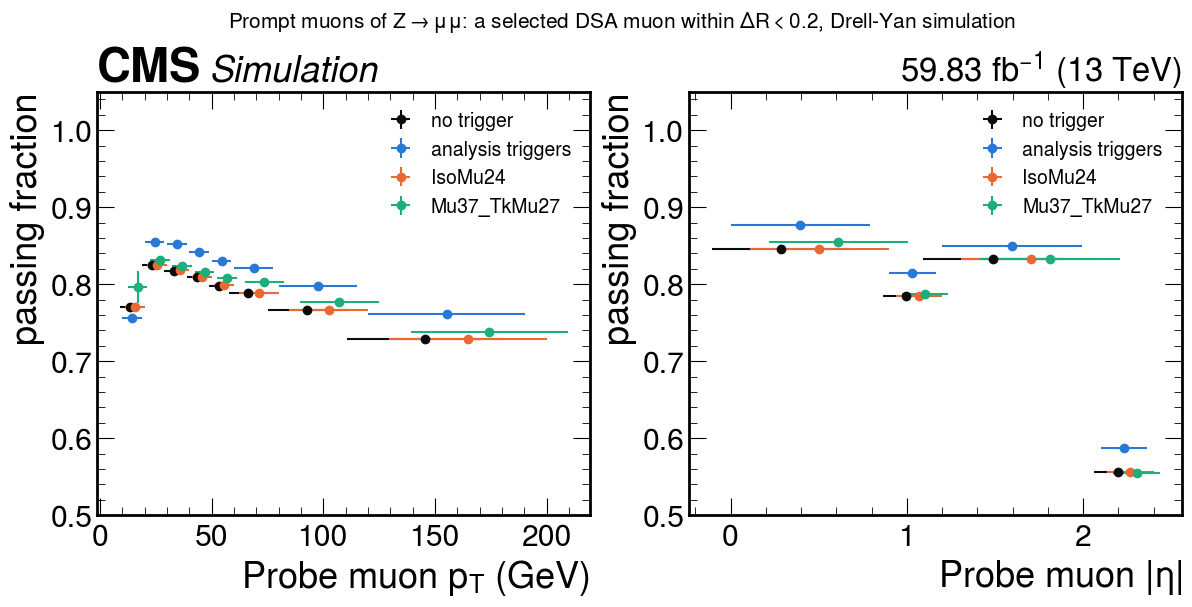


all probes, no trigger        : 0.8108 +- 0.0001 (5.64e+07 probes)
all probes, analysis triggers : 0.8437 +- 0.0001 (4.64e+07 probes)
all probes, IsoMu24           : 0.8110 +- 0.0001 (5.62e+07 probes)
all probes, Mu37_TkMu27       : 0.8167 +- 0.0001 (4.62e+07 probes)


In [4]:
spec = sysstudy.DSA_CR["Z -> mumu, DSA"]
h_z = summed(inputs, "Z -> mumu, DSA", DY)
z_results = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, axis in zip(axes, ("probe_pt", "probe_abseta")):
    results = {}
    for label, sel in TRIGGERS.items():
        h = h_z[sel] if sel else h_z
        h = h[{k: sum for k in ("trig_analysis", "trig_isomu24", "trig_tkmu", "probe_tight") if k not in sel}]
        results[label] = r = sysstudy.probe_efficiency(h, spec, axis)
        show(f"{label}, {axis}", r)
    z_results[axis] = results
    sysstudy.plot_probe_efficiency(results, ax=ax, offset=0.12)
    ax.set_ylim(0.5, 1.05)
fig.suptitle(r"Prompt muons of $Z \to \mu\mu$: a selected DSA muon within $\Delta R < 0.2$, Drell-Yan simulation",
             fontsize=15, y=1.03)
pt.cms_label(axes)
save(fig, "dsa_z_efficiency_triggers")
plt.show()

print()
for label, sel in TRIGGERS.items():
    h = h_z[sel] if sel else h_z
    h = h[{k: sum for k in ("trig_analysis", "trig_isomu24", "trig_tkmu", "probe_tight") if k not in sel}]
    eff, err, n = sysstudy.integrated_efficiency(h, spec)
    print(f"all probes, {label:18s}: {eff:.4f} +- {err:.4f} ({n:.3g} probes)")

**Interpretation.** Without a trigger, 81.1% of the prompt muons of $Z \to \mu\mu$ have a
selected DSA muon within $\Delta R < 0.2$: 0.85 in the barrel ($|\eta| < 0.9$), 0.79 where barrel
and endcap overlap (0.9 to 1.2), 0.83 in the endcaps up to $|\eta|$ = 2.1 and 0.56 above. The
fraction falls slowly with $p_T$, from 0.83 at 20 to 30 GeV to 0.73 at 120 to 200 GeV. IsoMu24,
which the tag fires, leaves it unchanged (0.811); Mu37_TkMu27 raises it slightly (0.817); the
analysis triggers raise it to 0.844, by 3.3 points, because both their legs need a standalone muon,
which the probe then has more often. A measurement with the analysis triggers is therefore biased
upward by about 3 points; one with IsoMu24 is not.

The tight ID of the probe requires two matched muon stations, which the DSA reconstruction uses
as well, so a tight probe should have a DSA muon more often. Without a trigger:

every probe: 0-0.9: 0.846 +- 0.000, 0.9-1.2: 0.785 +- 0.000, 1.2-2.1: 0.832 +- 0.000, 2.1-2.4: 0.556 +- 0.000
tight probes: 0-0.9: 0.863 +- 0.000, 0.9-1.2: 0.795 +- 0.000, 1.2-2.1: 0.836 +- 0.000, 2.1-2.4: 0.565 +- 0.000
probes not tight: 0-0.9: 0.101 +- 0.001, 0.9-1.2: 0.191 +- 0.002, 1.2-2.1: 0.399 +- 0.002, 2.1-2.4: 0.143 +- 0.002


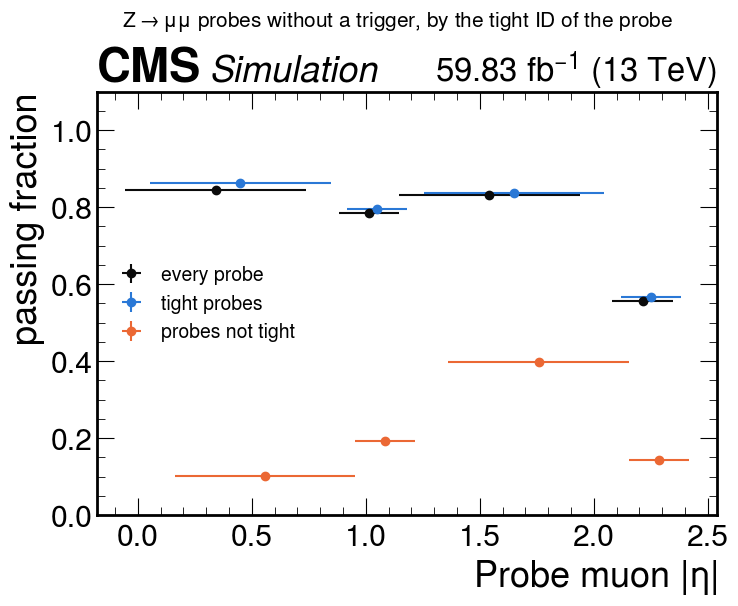

In [5]:
h0 = h_z[{"trig_analysis": sum, "trig_isomu24": sum, "trig_tkmu": sum}]
results = {"every probe": sysstudy.probe_efficiency(h0[{"probe_tight": sum}], spec, "probe_abseta"),
           "tight probes": sysstudy.probe_efficiency(h0[{"probe_tight": 1}], spec, "probe_abseta"),
           "probes not tight": sysstudy.probe_efficiency(h0[{"probe_tight": 0}], spec, "probe_abseta")}
for label, r in results.items():
    show(label, r)
fig, ax = plt.subplots(figsize=(8, 5.5))
sysstudy.plot_probe_efficiency(results, ax=ax, offset=0.12)
fig.suptitle(r"$Z \to \mu\mu$ probes without a trigger, by the tight ID of the probe", fontsize=15, y=1.03)
pt.cms_label(ax)
save(fig, "dsa_z_efficiency_tight")
plt.show()

**Interpretation.** About 98% of the probes are tight, so the tight ID of the probe hardly
matters: tight probes have a DSA muon 0.4 to 1.7 points more often than all probes. The few probes
that are not tight, with fewer matched muon stations, have one in only 10 to 40% of the cases.

## 4. Two collimated muons: J/ψ → μμ

The fraction of J/ψ probes whose two muons have two distinct selected DSA muons, and at least
one, against the separation of the muons and the pair's pT, in the background simulation (mostly
QCD, with its large event weights), without a trigger and with the analysis triggers.

two DSA muons, no trigger, probe_dR: 0-0.01: nan +- nan, 0.01-0.02: nan +- nan, 0.02-0.03: 1.000 +- 2.695, 0.03-0.05: 0.406 +- 0.052, 0.05-0.08: 0.583 +- 0.017, 0.08-0.12: 0.669 +- 0.011, 0.12-0.2: 0.461 +- 0.012, 0.2-0.4: 0.069 +- 0.007
two DSA muons, analysis triggers, probe_dR: 0-0.01: nan +- nan, 0.01-0.02: 0.133 +- 0.330, 0.02-0.03: 0.370 +- 0.080, 0.03-0.05: 0.562 +- 0.040, 0.05-0.08: 0.642 +- 0.017, 0.08-0.12: 0.737 +- 0.013, 0.12-0.2: 0.598 +- 0.020, 0.2-0.4: 0.144 +- 0.024
at least one, no trigger, probe_dR: 0-0.01: nan +- nan, 0.01-0.02: nan +- nan, 0.02-0.03: 1.256 +- 2.200, 0.03-0.05: 0.776 +- 0.067, 0.05-0.08: 0.921 +- 0.015, 0.08-0.12: 0.922 +- 0.007, 0.12-0.2: 0.898 +- 0.007, 0.2-0.4: 0.841 +- 0.016
two DSA muons, no trigger, probe_pt: 20-30: 0.126 +- 0.018, 30-40: 0.183 +- 0.012, 40-50: 0.436 +- 0.017, 50-60: 0.485 +- 0.016, 60-80: 0.476 +- 0.011, 80-100: 0.516 +- 0.014, 100-150: 0.485 +- 0.016, 150-300: 0.362 +- 0.057
two DSA muons, analysis triggers, probe_pt: 20-30: 

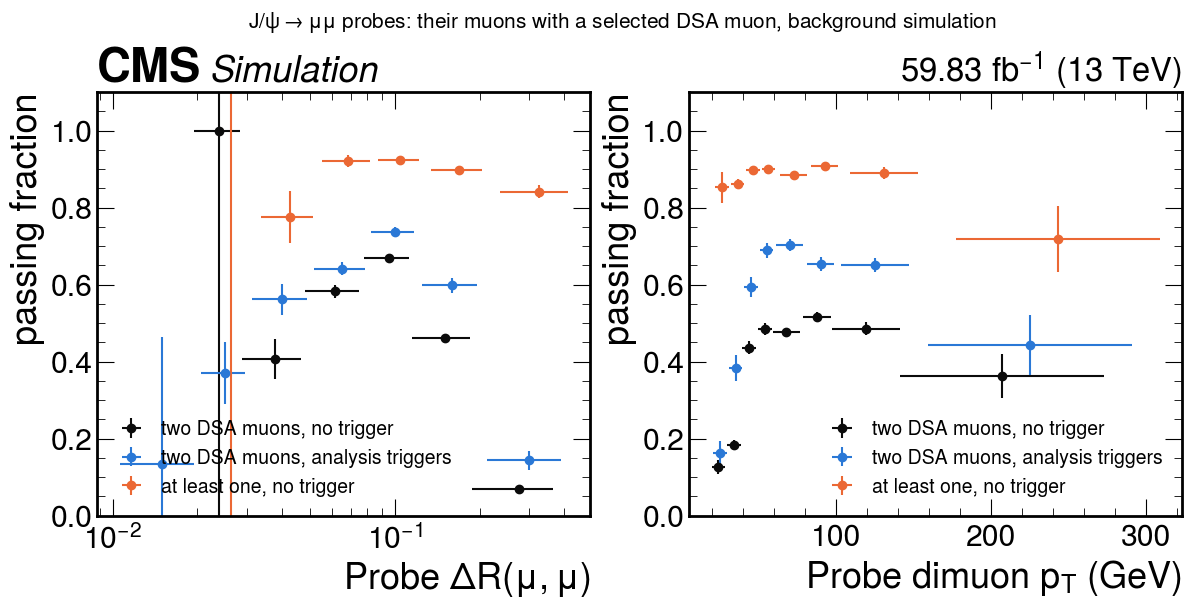

In [6]:
spec_j = sysstudy.DSA_CR["J/psi -> mumu, DSA"]
h_j = summed(inputs, "J/psi -> mumu, DSA")
j_results = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, axis in zip(axes, ("probe_dR", "probe_pt")):
    results = {}
    for label, sel, passing in (("two DSA muons, no trigger", {}, (2,)),
                                ("two DSA muons, analysis triggers", {"trig_analysis": 1}, (2,)),
                                ("at least one, no trigger", {}, (1, 2))):
        h = h_j[sel] if sel else h_j[{"trig_analysis": sum}]
        results[label] = r = sysstudy.probe_efficiency(h, spec_j, axis, passing=("n_dsa", passing))
        show(f"{label}, {axis}", r)
    j_results[axis] = results
    sysstudy.plot_probe_efficiency(results, ax=ax, offset=0.12)
    if axis == "probe_dR":
        ax.set_xscale("log")
fig.suptitle(r"$J/\psi \to \mu\mu$ probes: their muons with a selected DSA muon, background simulation",
             fontsize=15, y=1.03)
pt.cms_label(axes)
save(fig, "dsa_jpsi_count")
plt.show()

**Interpretation.** Two collimated muons are much harder for the DSA reconstruction than
one. Without a trigger, both muons of a $J/\psi$ have their own selected DSA muon in 44 to 52% of
the cases from 40 to 150 GeV, against the 66% that two independent muons at 0.81 each would give,
and in only 13 to 18% below 40 GeV. Against the separation the fraction peaks at 0.67 for
$\Delta R$ from 0.08 to 0.12 and falls for closer pairs (0.41 from 0.03 to 0.05) and for wider ones,
which are the softer $J/\psi$ ($\Delta R \approx 2m/p_T$; 0.07 from 0.2 to 0.4). At least one of
the two has a DSA muon in 78 to 92% of the cases. The analysis triggers raise the fraction with two
DSA muons by 0.14 to 0.23 from 30 to 150 GeV, much more than for single muons, since both their
legs need a standalone muon. Below $\Delta R$ = 0.03 there are too few probes: the fractions there,
one of them above one, are fluctuations of the subtraction.

## 5. What this gives, and what a data measurement needs

**In simulation.** About 81% of prompt muons have a selected DSA muon (0.85 in the barrel, 0.56
above $|\eta|$ = 2.1). For two collimated muons both have one only about half of the time above
40 GeV, well below the product of the single-muon fractions, so the DSA part of the muon-type
lepton jets cannot be inferred from single muons. The displaced ID has no impact-parameter
requirement, so prompt muons test it.

**In data** (a proposal; nothing here reads data). The same $Z \to \mu\mu$ tag and probe would
measure the single-muon fraction, and its ratio to the simulation would give a scale factor for
DSA muons. It needs:

1. A trigger that does not bias the probe. The analysis triggers raise the fraction by 3.3 points
   for single muons and by 0.14 to 0.23 for pairs. Data and simulation would both carry that bias,
   so their ratio could still serve if the simulation models how the triggers correlate with the
   DSA reconstruction, which this sample cannot check by itself. IsoMu24 fired by the tag avoids
   the question.
2. Data that hold such events. Our DoubleMuon ntuples are skimmed on the analysis triggers
   (`trigger_muPtCut`), so the measurement needs SingleMuon ntuples of 2018 (or unskimmed
   DoubleMuon), which we do not have yet, and a data campaign over them.
3. The group's approval, as for every use of data here. The region holds prompt $Z \to \mu\mu$
   events, far from the signal, and would be judged in simulation with the safety criteria first.

For pairs, $J/\psi \to \mu\mu$ selected by the analysis triggers carries the same bias, larger, and
the simulation has 5,600 effective events; the most collimated pairs ($\Delta R$ below 0.03) are not
reached at all. Questions for the group: whether to produce SingleMuon ntuples for this
measurement, and whether the pair efficiency can come from the simulation with an uncertainty set
by the single-muon scale factor.

The figures and the passing fractions go to EOS, and the local working directory is removed.

In [7]:
import json
table = {axis: {label: {k: np.asarray(v).tolist() for k, v in r.items() if k != "axis"}
                for label, r in results.items()}
         for axis, results in {**{f"z_{a}": r for a, r in z_results.items()},
                               **{f"jpsi_{a}": r for a, r in j_results.items()}}.items()}
with open(WORK / "passing_fractions.json", "w") as f:
    json.dump(table, f, indent=1)
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_cr_v3_results/dsa_prompt
